<a href="https://colab.research.google.com/github/lydiapelton/BA305-Project/blob/main/Lydia_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importing Data from :

https://archive.ics.uci.edu/dataset/2/adult

In [52]:
# installing package to import data
!pip install ucimlrepo

In [53]:
# IMPORTING DATA

from ucimlrepo import fetch_ucirepo

# fetch dataset
adult = fetch_ucirepo(id=2)

# data (as pandas dataframes)
X = adult.data.features
y = adult.data.targets

# metadata
print(adult.metadata)

# variable information
print(adult.variables)


{'uci_id': 2, 'name': 'Adult', 'repository_url': 'https://archive.ics.uci.edu/dataset/2/adult', 'data_url': 'https://archive.ics.uci.edu/static/public/2/data.csv', 'abstract': 'Predict whether annual income of an individual exceeds $50K/yr based on census data. Also known as "Census Income" dataset. ', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 48842, 'num_features': 14, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Income', 'Education Level', 'Other', 'Race', 'Sex'], 'target_col': ['income'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1996, 'last_updated': 'Tue Sep 24 2024', 'dataset_doi': '10.24432/C5XW20', 'creators': ['Barry Becker', 'Ronny Kohavi'], 'intro_paper': None, 'additional_info': {'summary': "Extraction was done by Barry Becker from the 1994 Census database.  A set of reasonably clean records was extracted using the fol

# Investigating Data

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [55]:
ogdf = pd.concat([X, y], axis=1)
display(ogdf.head())

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [57]:
ogdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [58]:
# TOTAL OBSERVATIONS = 48842
# TOTAL COLUMNS = 15

ogdf.shape

(48842, 15)

In [59]:
# FINDING NULL VALUES

null_values_per_column = ogdf.isnull().sum()
display(null_values_per_column)

# PROBLEMATIC COLUMNS = 'workclass', 'occupation', 'native-country'

,0
age,0
workclass,963
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,966
relationship,0
race,0
sex,0


In [60]:
# FINDING % OF NULL VALUES RELATIVE TO DF

total_observations = ogdf.shape[0]

for column in ['workclass', 'occupation', 'native-country']:
    null_count = null_values_per_column[column]
    percentage_null = (null_count / total_observations) * 100
    print(f"Percentage of null values in '{column}': {percentage_null:.2f}%")


# workclass = 1.97%
# occupation = 1.98%
# native-country = 0.56%

Percentage of null values in 'workclass': 1.97%
Percentage of null values in 'occupation': 1.98%
Percentage of null values in 'native-country': 0.56%


## Cleaning Data

In [61]:
# Drop rows where 'workclass', 'occupation', or 'native-country' have null values
df_no_na = ogdf.dropna(subset=['workclass', 'occupation', 'native-country'])

# Display the new shape and the number of dropped rows
print(f"Original shape: {ogdf.shape}")
print(f"Cleaned shape: {df_no_na.shape}")
print(f"Number of rows dropped: {len(adult_df) - len(adult_df_cleaned)}")

# Preview the cleaned DataFrame
display(df_no_na.tail())

# 1,221 dropped

Original shape: (48842, 15)
Cleaned shape: (47621, 15)
Number of rows dropped: 3620


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
48836,33,Private,245211,Bachelors,13,Never-married,Prof-specialty,Own-child,White,Male,0,0,40,United-States,<=50K.
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,<=50K.
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,<=50K.
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,<=50K.
48841,35,Self-emp-inc,182148,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,60,United-States,>50K.


In [62]:
# Found 4 diff income inputs
# Training set > 50k VS Testing set >50k.

df_no_na['income'].value_counts()

,count
income,
<=50K,24720
<=50K.,11360
>50K,7841
>50K.,3700


consolidating income to 2 diff income values by dropping the period

In [69]:
df_50k_fix = df_no_na.copy()
df_50k_fix['income'] = df_50k_fix['income'].str.replace('.', '', regex=False)
df_50k_fix['income'].value_counts()

,count
income,
<=50K,36080
>50K,11541


found more Null values that had ? instead

In [70]:
# values with "?"

(df_50k_fix == '?').sum()

# workclass, occupation, and native country all have ? in data

,0
age,0
workclass,1836
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,1843
relationship,0
race,0
sex,0


In [73]:
# changing the ? values into NaN values so that they can be dropped with dropna

df_q_fix = df_50k_fix.replace('?', np.nan).dropna()
(df_q_fix == '?').sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


In [75]:
# checking for white space in names

for col in df_q_fix.select_dtypes(include='object').columns:
    has_space = (df_q_fix[col] != df_q_fix[col].str.strip()).any()
    print(col, has_space)

workclass False
education False
marital-status False
occupation False
relationship False
race False
sex False
native-country False
income False


In [76]:
#checking for duplicates

df_q_fix.duplicated().sum()

np.int64(47)

In [77]:
# looking into the 47 flagged duplicates

df_q_fix[df_q_fix.duplicated(keep=False)].sort_values(list(df_q_fix.columns))

# since they are so few, they wont effect data, and could just be crazy coincidences. + the only crazy coincidence part is final weight, and we are dropping that anyway.

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
24667,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
36713,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
36461,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
48521,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
17673,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21875,49,Private,31267,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
7053,49,Self-emp-not-inc,43479,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
22494,49,Self-emp-not-inc,43479,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
2303,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K


# Encoding step of cleaning:

## Starting with income <=50 k vs. >50K

## =50k : 0
## >50k : 1

In [92]:
# code income to be 0 and 1

dfbinaryinc = df_q_fix.copy()
dfbinaryinc['income'] = dfbinaryinc['income'].map({'<=50K': 0, '>50K': 1})
dfbinaryinc['income'].value_counts()

,count
income,
0,34014
1,11208


In [93]:
# baseline ratio for the clean data set:

baseline = dfbinaryinc['income'].value_counts(normalize=True).max()
print(f'Baseline accuracy: {baseline:.1%}')

Baseline accuracy: 75.2%


baseline accuracy of 75.2% means if the model always predicts >50k, the model will be right 75% of the time.

Looking at dropping either education or education_num (redundant)

In [94]:
pd.crosstab(dfbinaryinc['education'], dfbinaryinc['education-num'])

# perfect one to one match bc each row only has one non-zero number

education-num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
education,,,,,,,,,,,,,,,,
10th,0,0,0,0,0,1223,0,0,0,0,0,0,0,0,0,0
11th,0,0,0,0,0,0,1619,0,0,0,0,0,0,0,0,0
12th,0,0,0,0,0,0,0,577,0,0,0,0,0,0,0,0
1st-4th,0,222,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5th-6th,0,0,449,0,0,0,0,0,0,0,0,0,0,0,0,0
7th-8th,0,0,0,823,0,0,0,0,0,0,0,0,0,0,0,0
9th,0,0,0,0,676,0,0,0,0,0,0,0,0,0,0,0
Assoc-acdm,0,0,0,0,0,0,0,0,0,0,0,1507,0,0,0,0
Assoc-voc,0,0,0,0,0,0,0,0,0,0,1959,0,0,0,0,0


dropping education and keeping education_num bc it is already in a numeric format

In [95]:
df_no_catedu = dfbinaryinc.drop(columns=['education']).copy()
df_no_catedu.shape

# lost one feature 15->14

(45222, 14)

Looking at Native Country feature
* has 40 unique values

In [96]:
df_no_catedu['native-country'].value_counts(normalize=True).round(3)

# 91% of the data is US born, not enough non native to justify making 40 new columns, would make data noisier and cause overfitting

,proportion
native-country,
United-States,0.913
Mexico,0.020
Philippines,0.006
Germany,0.004
Puerto-Rico,0.004
Canada,0.004
El-Salvador,0.003
India,0.003
Cuba,0.003


In [97]:
# grouping native country into US vs other

df_country = df_no_catedu.copy()
df_country['native-country'] = np.where(df_country['native-country'] == 'United-States', 'United-States', 'Other')
df_country['native-country'].value_counts()

,count
native-country,
United-States,41292
Other,3930


Encoding the other categorical variables

In [98]:
# looking at the change in column #

text_cols = df_country.select_dtypes(include='object').columns
summary = pd.DataFrame({
    'categories': df_country[text_cols].nunique(),
    'binary_columns_after_drop_first': df_country[text_cols].nunique() - 1
})
print(summary)
print('\nTotal new binary columns:', summary['binary_columns_after_drop_first'].sum())
print('Numeric columns kept:', len(df_country.columns) - len(text_cols))

                categories  binary_columns_after_drop_first
workclass                7                                6
marital-status           7                                6
occupation              14                               13
relationship             6                                5
race                     5                                4
sex                      2                                1
native-country           2                                1

Total new binary columns: 36
Numeric columns kept: 7


In [99]:
# cleaned and encoded df = encodeddf

encodeddf = pd.get_dummies(df_country, drop_first=True, dtype=int)
encodeddf.shape

(45222, 43)

In [100]:
# dropping fnlwgt justification - it is just the weight a person holds in the census, no correl with income
# could confuse the model and cause overfitting

encodeddf['fnlwgt'].corr(encodeddf['income'])


np.float64(-0.007263912940611196)

In [101]:
dfclean = df_encoded.drop(columns=['fnlwgt']).copy()
dfclean.shape

(45222, 42)

# Train / Test Split
## Start here

# Outliers

After initial cleaning (Null values and data entry errors) we get adult_df_clean

Now we will investigate outliers, that could confuse our predictive models


In [14]:
# display the number of columns in adult_df_cleaned that are numeric

num_cols = adult_df_cleaned.select_dtypes(include=['int64', 'float64']).columns
print(f"Number of numeric columns: {len(num_cols)}")

# so we should show 6 boxplots below:

Number of numeric columns: 6


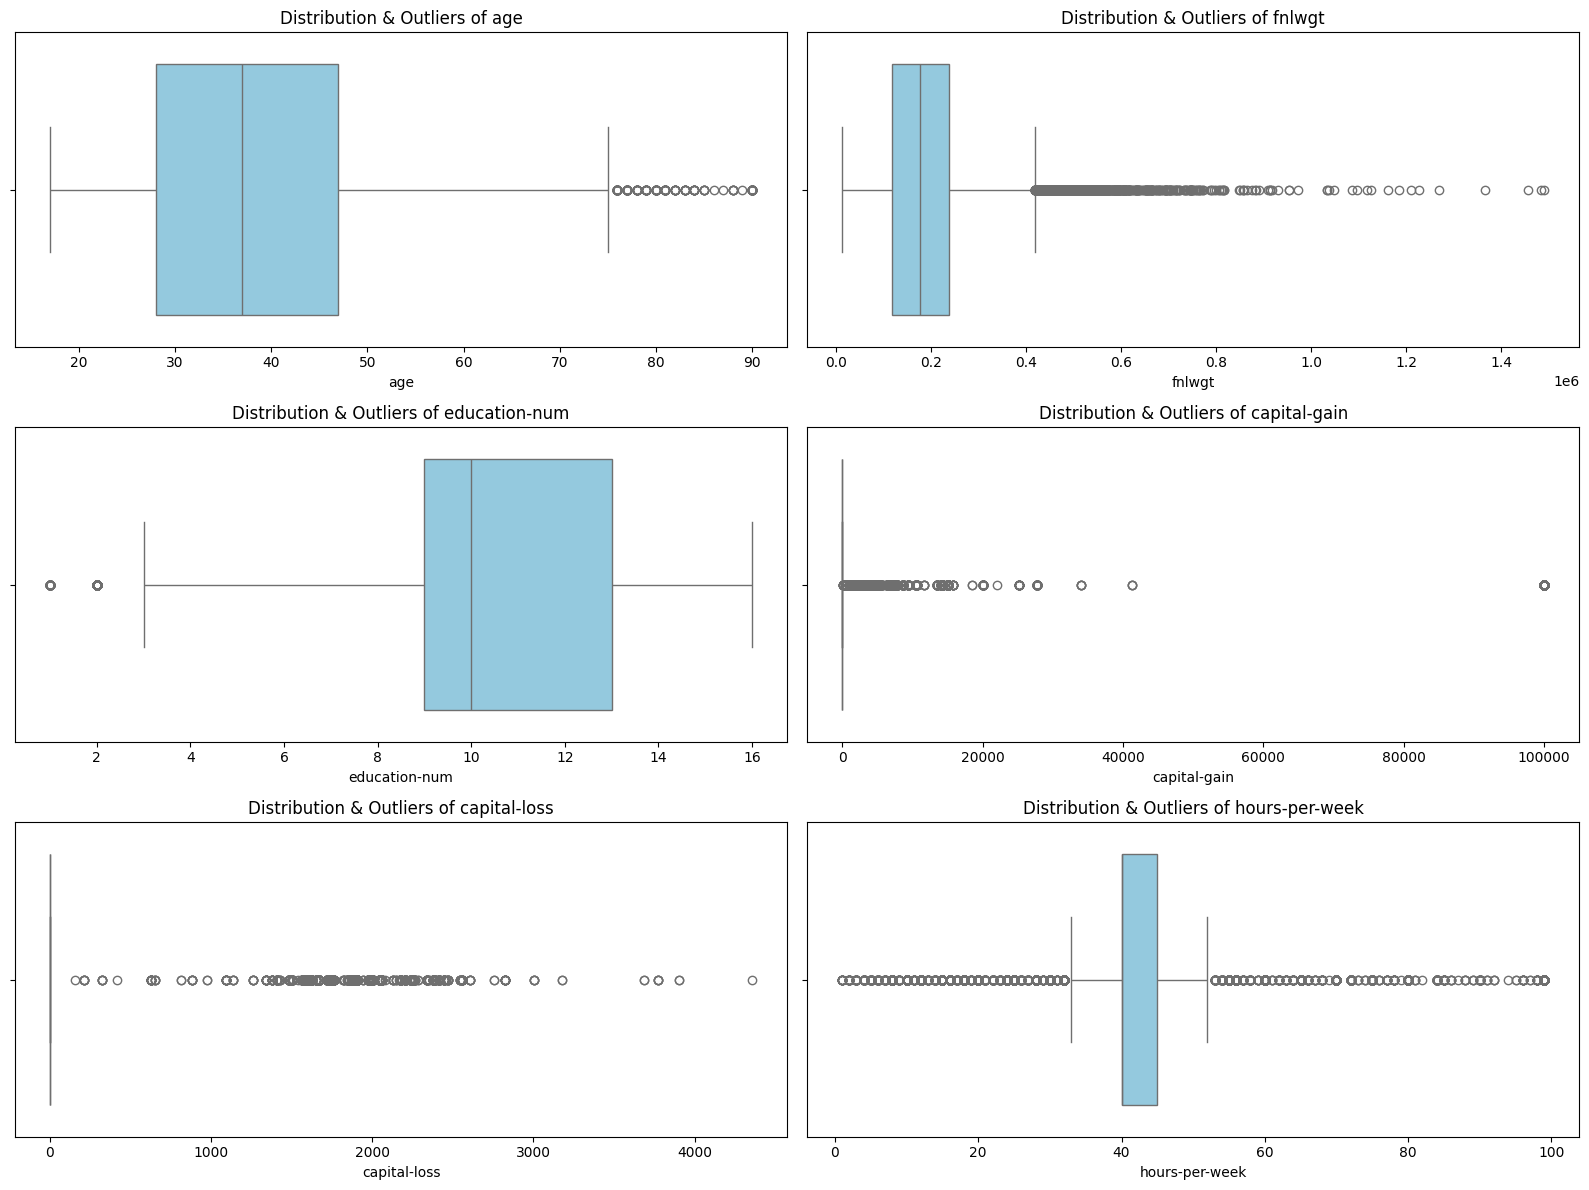

In [15]:
num_cols = adult_df_cleaned.select_dtypes(include=['int64', 'float64']).columns
num_plots = len(num_cols)

fig, axes = plt.subplots(nrows=(num_plots + 1) // 2, ncols=2, figsize=(16, 4 * ((num_plots + 1) // 2)))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(x=adult_df_cleaned[col], ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribution & Outliers of {col}', fontsize=12)
    axes[i].set_xlabel(col)

# Hide unused subplots if any
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Age Distribution
* outliers are people of retired age, could effect income prediction

Fnlwgt Distribution
* will likely end up dropping this feature as it is not predictive

Education Num Distribution
* few outliers, not concerned

Capital Gain Distribution
* all + values are outliers bc the majority of people do not trade and make gain

Capital Loss Distribution
* all - values are outliers bc the majority of people do not trade and make losses

Hours per week Distribution
* interesting that there are so many outliers


# Looking at Categorical Variables

## Investigating dropping non numeric values or making binary

In [16]:
# Calculate the number of columns resulting from making them all have dummy variables
numeric_cols = adult_df_cleaned.select_dtypes(include='number').columns
non_numeric_cols = adult_df_cleaned.select_dtypes(exclude='number').columns

total_original_numeric = len(numeric_cols)
new_one_hot_cols_count = 0

print("Columns and their unique value counts (binary/one-hot columns to be created):")
for col in non_numeric_cols:
    unique_count = adult_df_cleaned[col].nunique()
    print(f"- {col}: {unique_count} unique values")
    # If we use one-hot encoding, each unique value becomes a column (or unique_count - 1 if we drop first to avoid collinearity)
    new_one_hot_cols_count += unique_count

print(f"\nTotal numeric columns: {total_original_numeric}")
print(f"Total columns if we use dummy variables: {total_original_numeric + new_one_hot_cols_count}")
print(f"Total columns if we use dummy variables: (dropping initial row): {total_original_numeric + new_one_hot_cols_count - len(non_numeric_cols)}")

Columns and their unique value counts (binary/one-hot columns to be created):
- workclass: 7 unique values
- education: 16 unique values
- marital-status: 7 unique values
- occupation: 14 unique values
- relationship: 6 unique values
- race: 5 unique values
- sex: 2 unique values
- native-country: 41 unique values
- income: 2 unique values

Total numeric columns: 6
Total columns if we use dummy variables: 106
Total columns if we use dummy variables: (dropping initial row): 97


In [17]:
# 1. Keep a copy of the cleaned dataset for encoding
prepared_df = adult_df_cleaned.copy()

# 2. Drop redundant 'education' column and keep 'education-num', and final weight bc it is not a predicter (??????????)
prepared_df = prepared_df.drop(columns=['education', 'fnlwgt'])

# 3. Binary map the 'sex' column directly (0 for Female, 1 for Male)
prepared_df['sex'] = prepared_df['sex'].str.strip().map({'Female': 0, 'Male': 1}) # is this okay to be binary or should it be dummy

# 4. Simplify 'native-country' to US (1) and Non-US (0)
prepared_df['native-country'] = prepared_df['native-country'].str.strip()
prepared_df['native-country'] = (prepared_df['native-country'] == 'United-States').astype(int)

# 5. Make income binary: 1 = over $50K, 0 = $50K or under
prepared_df['income'] = (prepared_df['income'] == '>50K').astype(int)

# our updated columns and dataset preview!
print(f"New dataset shape: {prepared_df.shape}")
display(prepared_df.head())

New dataset shape: (45222, 13)


,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,1,2174,0,40,1,0
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,1,0,0,13,1,0
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,1,0,0,40,1,0
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,1,0,0,40,1,0
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,0,0,0,40,0,0


In [18]:
prepared_df['income'].value_counts()

,count
income,
0,34014
1,11208


In [19]:
# Turn the remaining word columns into binary (0/1) columns
encoded_df = pd.get_dummies(
    prepared_df,
    columns=['workclass', 'marital-status', 'occupation', 'relationship', 'race'],
    drop_first=True,
    dtype=int
)

print(f"Encoded dataset shape: {encoded_df.shape}")
display(encoded_df.head())


# ??? is this too many columns, if so what strategy do you recommend

Encoded dataset shape: (45222, 42)


,age,education-num,sex,capital-gain,capital-loss,hours-per-week,native-country,income,workclass_Local-gov,workclass_Private,...,occupation_Transport-moving,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White
0,39,13,1,2174,0,40,1,0,0,0,...,0,1,0,0,0,0,0,0,0,1
1,50,13,1,0,0,13,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,38,9,1,0,0,40,1,0,0,1,...,0,1,0,0,0,0,0,0,0,1
3,53,7,1,0,0,40,1,0,0,1,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,0,40,0,0,0,1,...,0,0,0,0,0,1,0,1,0,0


In [20]:
prepared_df['workclass'].value_counts()

,count
workclass,
Private,33307
Self-emp-not-inc,3796
Local-gov,3100
State-gov,1946
Self-emp-inc,1646
Federal-gov,1406
Without-pay,21


## Starting to investigate Descriptive Question

In [21]:
# Correlation of every column with income, strongest positive at top

encoded_df.corr()['income'].sort_values(ascending=False)

,income
income,1.000000
marital-status_Married-civ-spouse,0.446192
education-num,0.332800
age,0.237040
hours-per-week,0.227199
capital-gain,0.221034
sex,0.215760
occupation_Exec-managerial,0.209176
occupation_Prof-specialty,0.183329
capital-loss,0.148687


In [22]:
# more clean data on correlation between income
income_corr = encoded_df.corr()['income'].drop('income')

print("Strongest POSITIVE (linked to earning over $50K):")
print(income_corr.sort_values(ascending=False).head(10))

print("\nStrongest NEGATIVE (linked to earning $50K or under):")
print(income_corr.sort_values().head(10))

Strongest POSITIVE (linked to earning over $50K):
marital-status_Married-civ-spouse    0.446192
education-num                        0.332800
age                                  0.237040
hours-per-week                       0.227199
capital-gain                         0.221034
sex                                  0.215760
occupation_Exec-managerial           0.209176
occupation_Prof-specialty            0.183329
capital-loss                         0.148687
workclass_Self-emp-inc               0.137845
Name: income, dtype: float64

Strongest NEGATIVE (linked to earning $50K or under):
marital-status_Never-married   -0.319536
relationship_Own-child         -0.222635
relationship_Not-in-family     -0.195561
occupation_Other-service       -0.165428
relationship_Unmarried         -0.147262
workclass_Private              -0.116721
occupation_Handlers-cleaners   -0.091692
race_Black                     -0.090405
relationship_Other-relative    -0.085604
occupation_Machine-op-inspct   -0.076

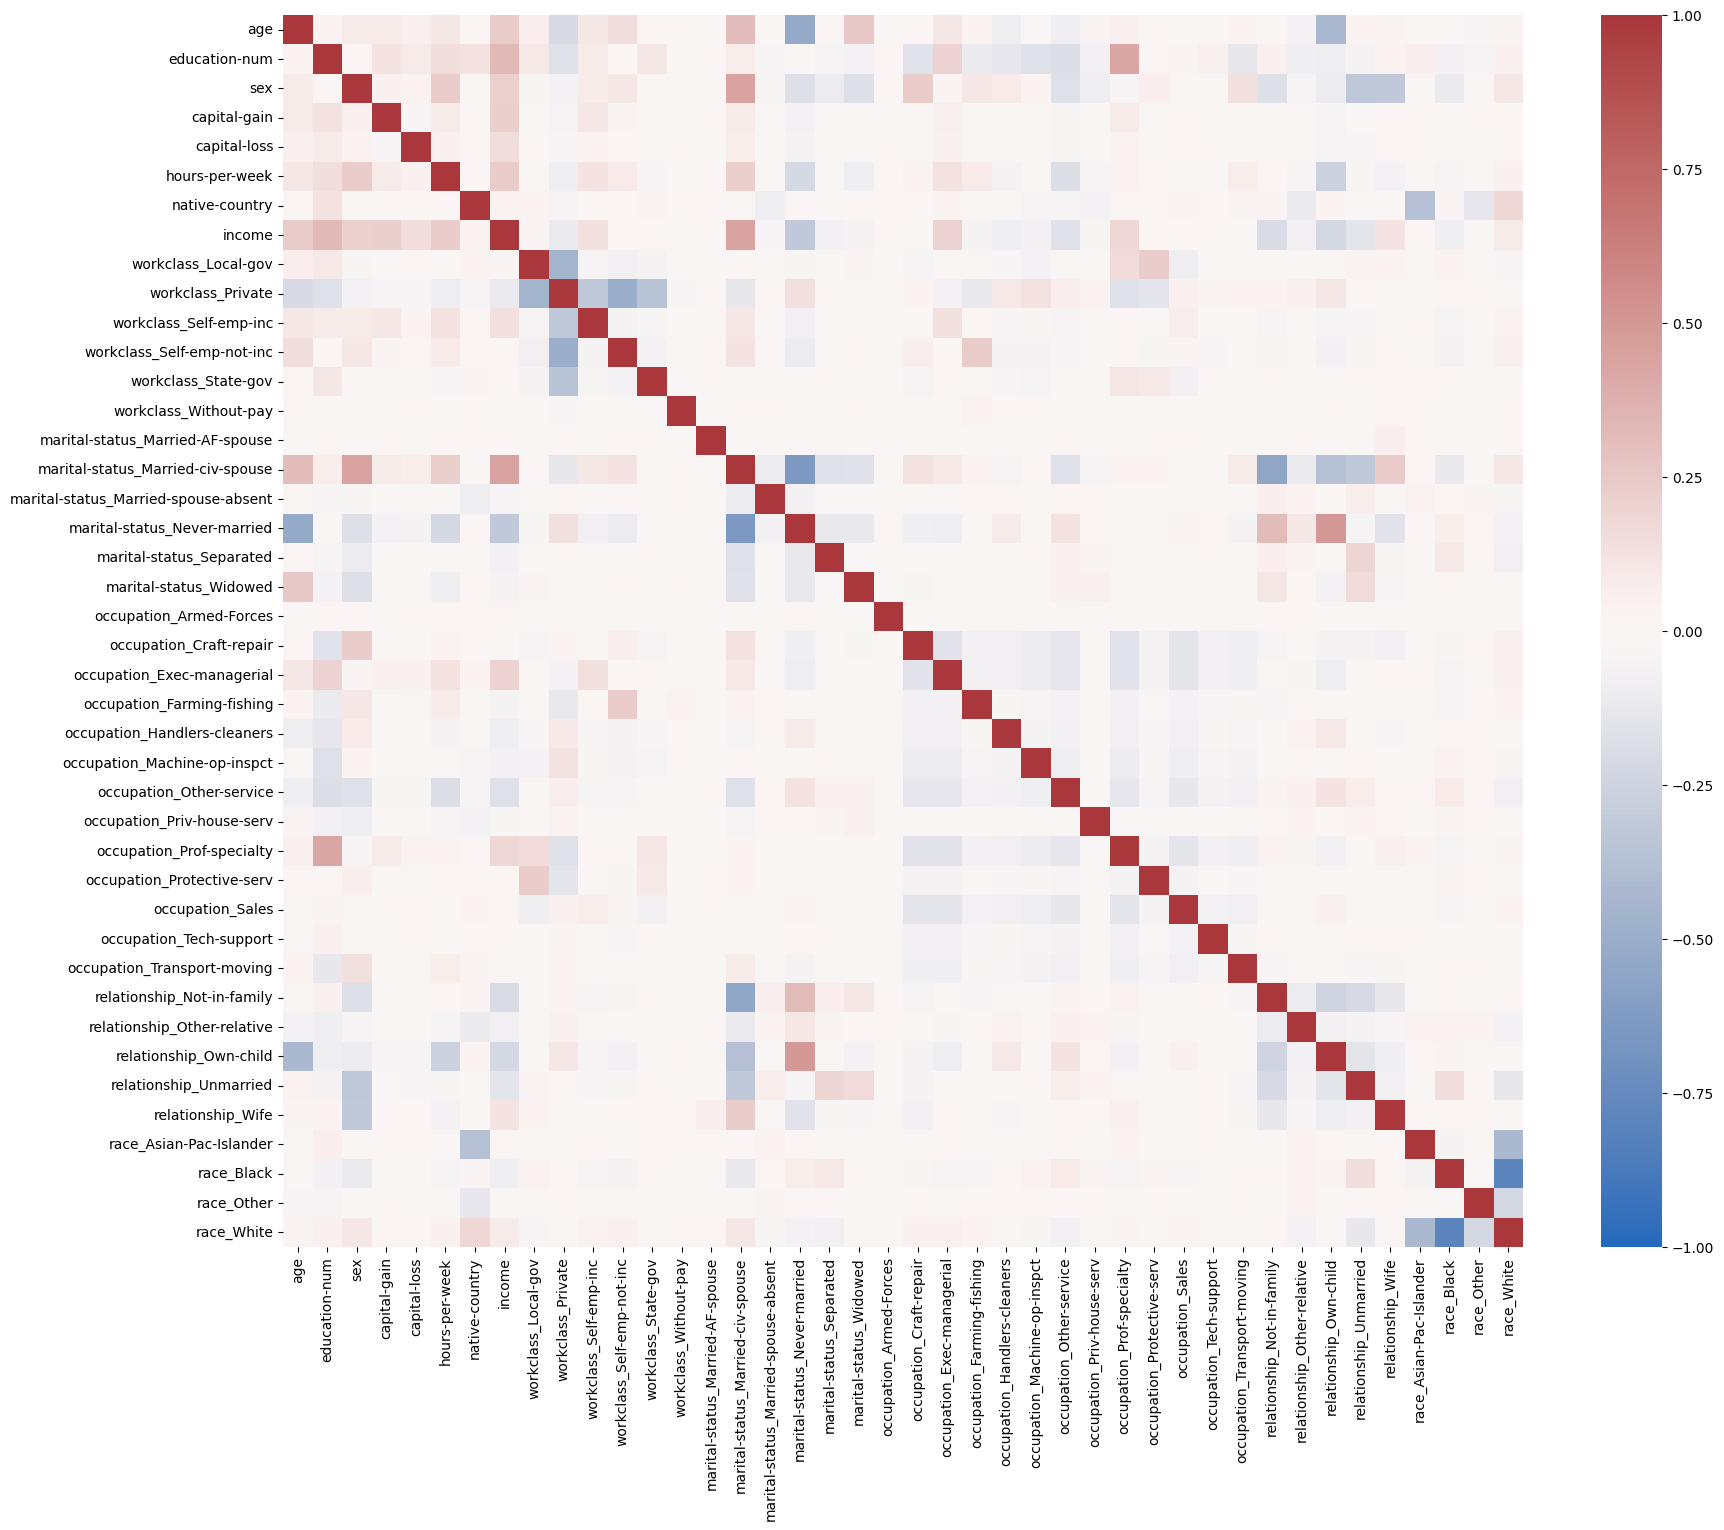

In [23]:
# correlation matrix

plt.figure(figsize=(20,16))
sns.heatmap(encoded_df.corr(), vmin=-1, vmax=1, cmap='vlag');

Next start PCA ??

In [24]:
# scaling data

from sklearn.preprocessing import StandardScaler

# Features only: everything except income
features = encoded_df.drop(columns=['income'])

# Scale so every column has mean 0 and std 1
scaler = StandardScaler()
scaled_df = pd.DataFrame(scaler.fit_transform(features), columns=features.columns)

# Check it worked
scaled_df.agg(['mean', 'std']).round(3)

,age,education-num,sex,capital-gain,capital-loss,hours-per-week,native-country,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,...,occupation_Transport-moving,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White
mean,-0.0,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0,0.0,...,-0.0,0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [25]:
#run PCA, name components, and show summary table

from sklearn.decomposition import PCA

# Run PCA on the scaled features (keep all components for now)
pcs = PCA()
scores = pcs.fit_transform(scaled_df)

# Name the components PC1, PC2, ...
pc_names = ['PC' + str(i+1) for i in range(pcs.n_components_)]
scores_df = pd.DataFrame(scores, columns=pc_names)

# Summary table: eigenvalue, % of variance, cumulative %
summary_df = pd.DataFrame({
    'Eigenvalue': pcs.explained_variance_,
    '% of variance': pcs.explained_variance_ratio_ * 100,
    'Cumulative %': np.cumsum(pcs.explained_variance_ratio_) * 100
}, index=pc_names)
summary_df.round(3)


# why is our PCA so weak?? is it okay for PCA to not be helpful? is this because we cleaned our data too much?

,Eigenvalue,% of variance,Cumulative %
PC1,3.254,7.937,7.937
PC2,2.161,5.271,13.208
PC3,2.052,5.006,18.214
PC4,1.727,4.211,22.425
PC5,1.591,3.880,26.305
PC6,1.501,3.660,29.966
PC7,1.411,3.440,33.406
PC8,1.328,3.240,36.646
PC9,1.194,2.913,39.559
PC10,1.163,2.838,42.396


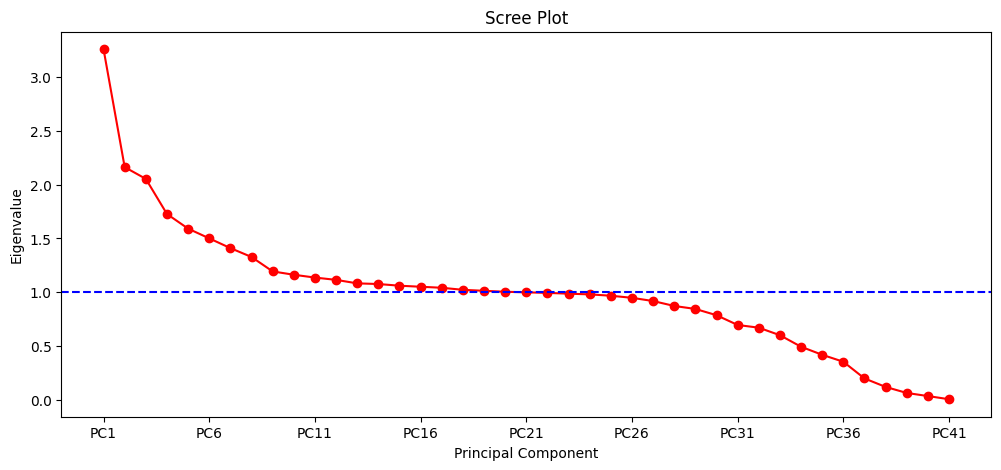

In [26]:
# Scree plot - shows how many PC we would need to even hit latent root

ax = summary_df['Eigenvalue'].plot(marker='o', color='red', figsize=(12,5))
ax.axhline(y=1, color='b', linestyle='--')   # eigenvalue = 1 cut-off line
ax.set_title('Scree Plot')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Eigenvalue');

In [27]:
# Loadings (weights): rows = original features, columns = PCs
loadings = pd.DataFrame(pcs.components_.T, index=scaled_df.columns, columns=pc_names)

# PC1's weights, biggest (positive or negative) first
loadings['PC1'].sort_values(key=abs, ascending=False).head(12)

,PC1
marital-status_Married-civ-spouse,0.439712
marital-status_Never-married,-0.397066
age,0.302938
relationship_Own-child,-0.288910
sex,0.257341
hours-per-week,0.239650
workclass_Private,-0.238321
occupation_Other-service,-0.188895
workclass_Self-emp-not-inc,0.174666
race_White,0.163790


# Starting on our Predictive Model

QUESTION :  Can we predict if an individual’s annual income exceeds $50,000 based on different demographics such as age, education, occupation, and marital status from 1994 consensus data?

In [28]:
# X = the 41 features, y = what we're predicting
X = encoded_df.drop(columns=['income'])
y = encoded_df['income']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (45222, 41)
y shape: (45222,)


In [29]:
# show all X columns
pd.set_option('display.max_columns', None)
display(X.head())

,age,education-num,sex,capital-gain,capital-loss,hours-per-week,native-country,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White
0,39,13,1,2174,0,40,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
1,50,13,1,0,0,13,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,38,9,1,0,0,40,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
3,53,7,1,0,0,40,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,0,40,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0


In [30]:
# splitting the data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y
)

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Share of >50K in full data:", round(y.mean(), 3))
print("Share of >50K in train:    ", round(y_train.mean(), 3))
print("Share of >50K in test:     ", round(y_test.mean(), 3))

Train rows: 31655 | Test rows: 13567
Share of >50K in full data: 0.248
Share of >50K in train:     0.248
Share of >50K in test:      0.248


In [31]:
# Scale using the TRAINING data only

model_scaler = StandardScaler()
X_train_scaled = model_scaler.fit_transform(X_train)   # learn mean/std from train, then scale train
X_test_scaled = model_scaler.transform(X_test)          # apply those same train numbers to test

print("Train mean (should be ~0):", round(X_train_scaled.mean(), 3))
print("Test mean (close to 0, not exact):", round(X_test_scaled.mean(), 3))

Train mean (should be ~0): 0.0
Test mean (close to 0, not exact): -0.002


In [32]:
# train model, show probability

from sklearn.linear_model import LogisticRegression

# Train the model on the scaled training data
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

# Probability each test person earns >$50K
y_probs = log_model.predict_proba(X_test_scaled)[:, 1]

# The model's 0/1 prediction (uses a 0.5 cutoff by default)
y_pred = log_model.predict(X_test_scaled)

# Look at the first few side by side
pd.DataFrame({'probability': y_probs, 'prediction': y_pred, 'actual': y_test.values}).head(10)

,probability,prediction,actual
0,0.015799,0,0
1,0.018014,0,0
2,0.739195,1,1
3,0.634088,1,1
4,0.006937,0,0
5,0.008766,0,0
6,0.121158,0,0
7,0.401342,0,0
8,0.815573,1,1
9,0.625864,1,1


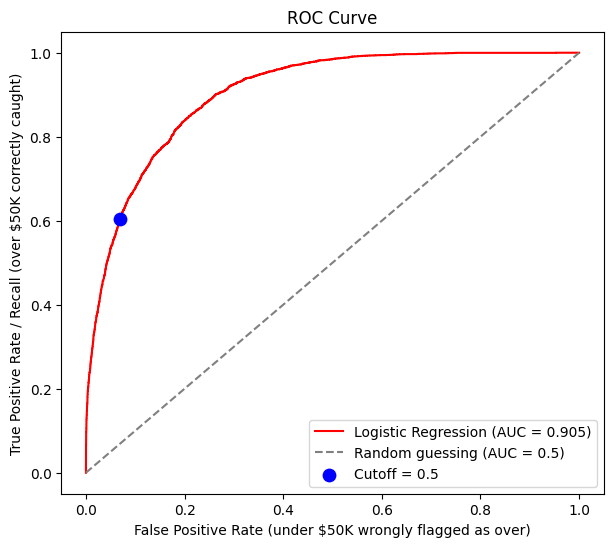

In [33]:
# ROC Curve

from sklearn.metrics import roc_curve, roc_auc_score

# True positive rate and false positive rate at every possible cutoff
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
auc = roc_auc_score(y_test, y_probs)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, color='red', label=f'Logistic Regression (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guessing (AUC = 0.5)')

# Mark where the default 0.5 cutoff sits on the curve
idx = np.argmin(np.abs(thresholds - 0.5))
plt.scatter(fpr[idx], tpr[idx], color='blue', s=80, zorder=5, label='Cutoff = 0.5')

plt.xlabel('False Positive Rate (under $50K wrongly flagged as over)')
plt.ylabel('True Positive Rate / Recall (over $50K correctly caught)')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


# Try a range of cutoffs and record the results
threshold_rows = []
for t in np.arange(0.3, 0.91, 0.05):
    preds = (y_probs >= t).astype(int)
    threshold_rows.append({
        'Threshold': round(t, 2),
        'Accuracy': round(accuracy_score(y_test, preds), 3),
        'Precision': round(precision_score(y_test, preds, zero_division=0), 3),
        'Recall': round(recall_score(y_test, preds), 3),
        'F1': round(f1_score(y_test, preds), 3),
        'Predicted >50K': preds.sum()
    })

threshold_table = pd.DataFrame(threshold_rows)
threshold_table

,Threshold,Accuracy,Precision,Recall,F1,Predicted >50K
0,0.30,0.827,0.620,0.777,0.690,4216
1,0.35,0.838,0.655,0.733,0.692,3761
2,0.40,0.844,0.685,0.688,0.686,3378
3,0.45,0.849,0.715,0.650,0.681,3057
4,0.50,0.849,0.740,0.603,0.665,2741
5,0.55,0.848,0.762,0.560,0.645,2470
6,0.60,0.845,0.792,0.506,0.618,2150
7,0.65,0.838,0.816,0.446,0.577,1836
8,0.70,0.830,0.840,0.387,0.530,1547
9,0.75,0.822,0.872,0.330,0.479,1274


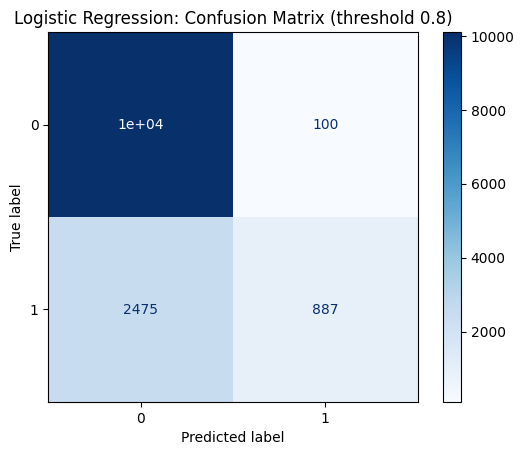

Accuracy:  0.81
Precision: 0.899
Recall:    0.264
F1 score:  0.408


In [35]:
# Apply a 0.8 cutoff: probability >= 0.8 becomes "over $50K"
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

y_pred_80 = (y_probs >= 0.8).astype(int)

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_80, cmap='Blues')
plt.title('Logistic Regression: Confusion Matrix (threshold 0.8)')
plt.show()

# Metrics at this cutoff
print("Accuracy: ", round(accuracy_score(y_test, y_pred_80), 3))
print("Precision:", round(precision_score(y_test, y_pred_80), 3))
print("Recall:   ", round(recall_score(y_test, y_pred_80), 3))
print("F1 score: ", round(f1_score(y_test, y_pred_80), 3))

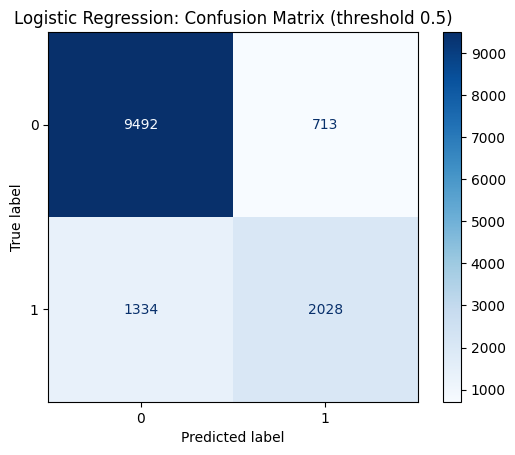

Accuracy:  0.849
Precision: 0.74
Recall:    0.603
F1 score:  0.665


In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title('Logistic Regression: Confusion Matrix (threshold 0.5)')
plt.show()

# Metrics
print("Accuracy: ", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:   ", round(recall_score(y_test, y_pred), 3))
print("F1 score: ", round(f1_score(y_test, y_pred), 3))

In [37]:
from sklearn.linear_model import LogisticRegression

# Train the model on the scaled training data
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

# Probability each test person earns >$50K
y_probs = log_model.predict_proba(X_test_scaled)[:, 1]

# The model's 0/1 prediction
y_pred = log_model.predict(X_test_scaled)

# Look at the first few side by side
pd.DataFrame({'probability': y_probs, 'prediction': y_pred, 'actual': y_test.values}).head(10)

,probability,prediction,actual
0,0.015799,0,0
1,0.018014,0,0
2,0.739195,1,1
3,0.634088,1,1
4,0.006937,0,0
5,0.008766,0,0
6,0.121158,0,0
7,0.401342,0,0
8,0.815573,1,1
9,0.625864,1,1


In [38]:
# can you create a table comparing accuracy on the test data vs the training data
# Predictions on the training data too
y_train_pred = log_model.predict(X_train_scaled)

# Compare metrics on train vs test
comparison = pd.DataFrame({
    'Train': [
        accuracy_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred),
        recall_score(y_train, y_train_pred),
        f1_score(y_train, y_train_pred)
    ],
    'Test': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ]
}, index=['Accuracy', 'Precision', 'Recall', 'F1'])

comparison['Difference'] = comparison['Train'] - comparison['Test']
comparison.round(3)

,Train,Test,Difference
Accuracy,0.847,0.849,-0.002
Precision,0.732,0.740,-0.008
Recall,0.604,0.603,0.001
F1,0.662,0.665,-0.003


In [39]:
# K fold cross validation , k = 5

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline

# Bundle scaling + model so each fold scales correctly
log_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# 5 folds, shuffled
folds = KFold(n_splits=5, shuffle=True, random_state=0)

# Accuracy on each fold
cv_accuracy = cross_val_score(log_pipeline, X, y, scoring='accuracy', cv=folds)
print("Accuracy on each fold:", cv_accuracy.round(3))
print("Average accuracy:     ", round(cv_accuracy.mean(), 3))

# F1 on each fold (the balance of precision and recall)
cv_f1 = cross_val_score(log_pipeline, X, y, scoring='f1', cv=folds)
print("\nF1 on each fold:      ", cv_f1.round(3))
print("Average F1:           ", round(cv_f1.mean(), 3))

Accuracy on each fold: [0.849 0.847 0.847 0.847 0.848]
Average accuracy:      0.848

F1 on each fold:       [0.663 0.657 0.672 0.661 0.661]
Average F1:            0.663


In [40]:
# K fold cross validation , k = 10

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline

# Bundle scaling + model so each fold scales correctly
log_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# 5 folds, shuffled
folds = KFold(n_splits=10, shuffle=True, random_state=0)

# Accuracy on each fold
cv_accuracy = cross_val_score(log_pipeline, X, y, scoring='accuracy', cv=folds)
print("Accuracy on each fold:", cv_accuracy.round(3))
print("Average accuracy:     ", round(cv_accuracy.mean(), 3))

# F1 on each fold (the balance of precision and recall)
cv_f1 = cross_val_score(log_pipeline, X, y, scoring='f1', cv=folds)
print("\nF1 on each fold:      ", cv_f1.round(3))
print("Average F1:           ", round(cv_f1.mean(), 3))

Accuracy on each fold: [0.847 0.851 0.846 0.849 0.851 0.842 0.852 0.843 0.847 0.847]
Average accuracy:      0.847

F1 on each fold:       [0.645 0.678 0.658 0.657 0.683 0.658 0.679 0.647 0.654 0.664]
Average F1:            0.662


## KNN

In [41]:
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 9, 15, 21, 31, 51]
k_rows = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    train_pred = knn.predict(X_train_scaled)
    test_pred = knn.predict(X_test_scaled)

    k_rows.append({
        'K': k,
        'Train Accuracy': round(accuracy_score(y_train, train_pred), 3),
        'Test Accuracy': round(accuracy_score(y_test, test_pred), 3),
        'Test F1': round(f1_score(y_test, test_pred), 3)
    })
    print("Done K =", k)

k_table = pd.DataFrame(k_rows)
k_table

Done K = 1
Done K = 3
Done K = 5
Done K = 9
Done K = 15
Done K = 21
Done K = 31
Done K = 51


,K,Train Accuracy,Test Accuracy,Test F1
0,1,0.970,0.795,0.581
1,3,0.893,0.818,0.612
2,5,0.874,0.824,0.619
3,9,0.861,0.831,0.627
4,15,0.852,0.836,0.637
5,21,0.847,0.837,0.636
6,31,0.842,0.836,0.635
7,51,0.838,0.836,0.634
